In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [3]:
df = pd.read_csv("student-por.csv")

In [5]:
print("Dataset preview:")
print(df.head())

Dataset preview:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        4   0  11  11  
1      5        3      3     1     1      3        2   9  11  11  
2      4        3      2     2     3      3        6  12  13  12  
3      3        2      2     1     1      5        0  14  14  14  
4      4        3      2     1     2      5        0  11  13  13  

[5 rows x 33 columns]


In [116]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [118]:
# Exploratory Data Analysis (EDA)
print("\nSummary statistics:")
print(df.describe())


Summary statistics:
              age        Medu        Fedu  traveltime   studytime    failures  \
count  649.000000  649.000000  649.000000  649.000000  649.000000  649.000000   
mean    16.744222    2.514638    2.306626    1.568567    1.930663    0.221880   
std      1.218138    1.134552    1.099931    0.748660    0.829510    0.593235   
min     15.000000    0.000000    0.000000    1.000000    1.000000    0.000000   
25%     16.000000    2.000000    1.000000    1.000000    1.000000    0.000000   
50%     17.000000    2.000000    2.000000    1.000000    2.000000    0.000000   
75%     18.000000    4.000000    3.000000    2.000000    2.000000    0.000000   
max     22.000000    4.000000    4.000000    4.000000    4.000000    3.000000   

           famrel    freetime       goout        Dalc        Walc      health  \
count  649.000000  649.000000  649.000000  649.000000  649.000000  649.000000   
mean     3.930663    3.180277    3.184900    1.502311    2.280431    3.536210   
std   

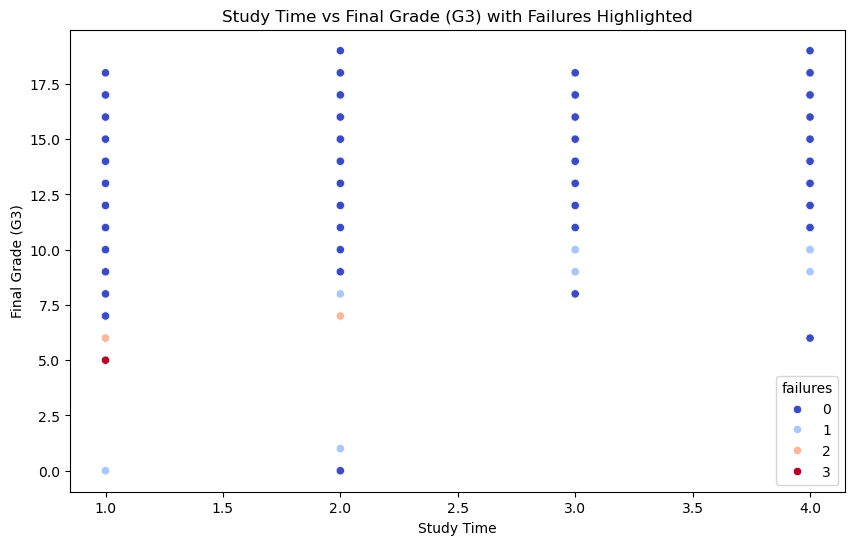

In [120]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='studytime', y='G3', hue='failures', palette='coolwarm')
plt.title("Study Time vs Final Grade (G3) with Failures Highlighted")
plt.xlabel("Study Time")
plt.ylabel("Final Grade (G3)")
plt.show()


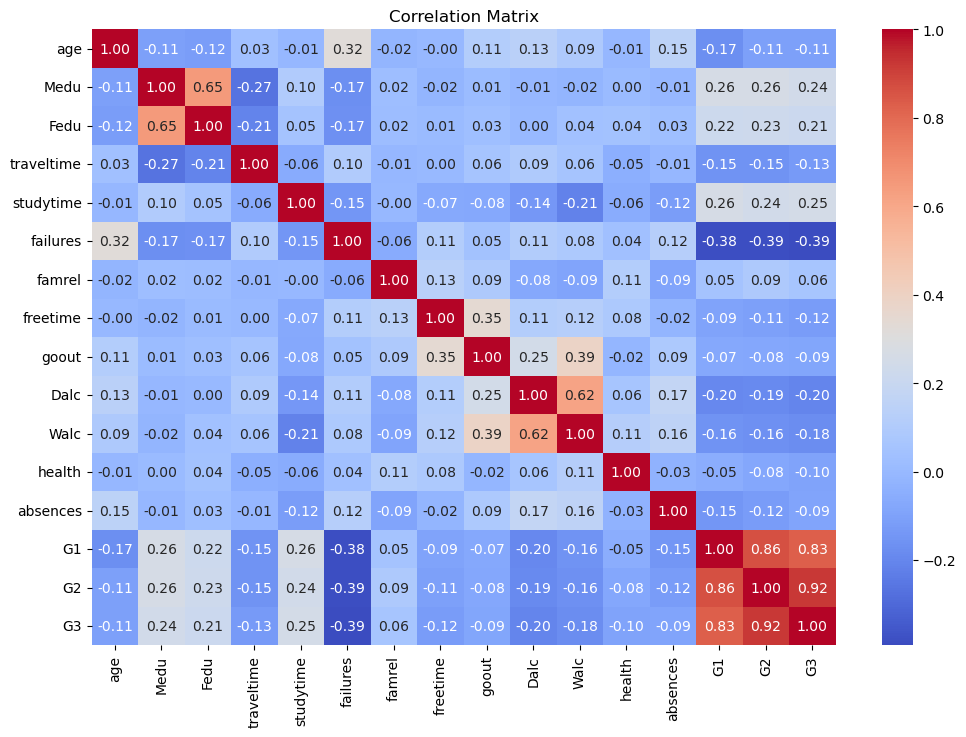

In [122]:
# Ensure only numeric columns are used for correlation
numeric_df = df.select_dtypes(include=['number'])

# Calculate and visualize the correlation matrix
plt.figure(figsize=(12, 8))
correlation_matrix = numeric_df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()


In [124]:
X = df[['studytime', 'G1', 'G2', 'failures']]  # Adjust features as needed
y = df['G3']

In [128]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [130]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [132]:
model = LinearRegression()
model.fit(X_train, y_train)


LinearRegression()

In [134]:
print("\nModel Coefficients:")
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)


Model Coefficients:
Coefficients: [ 0.08482373  0.46999431  2.51368014 -0.08312397]
Intercept: 11.79383429672447


In [136]:
y_pred = model.predict(X_test)

In [138]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

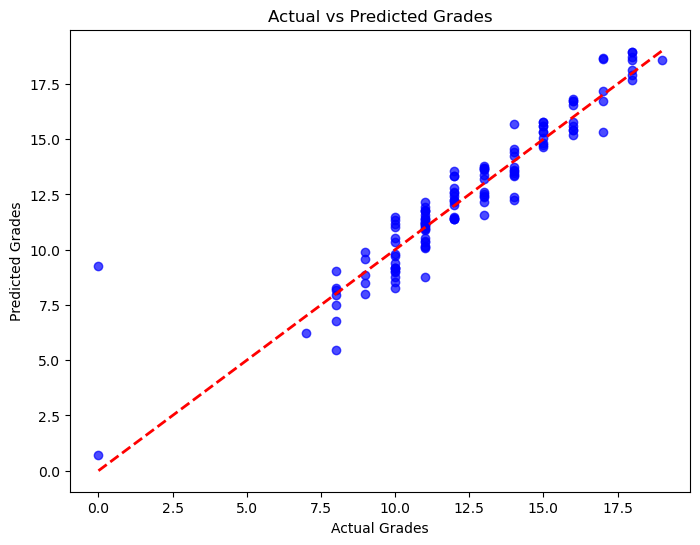

In [140]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', linewidth=2)
plt.title("Actual vs Predicted Grades")
plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")
plt.show()

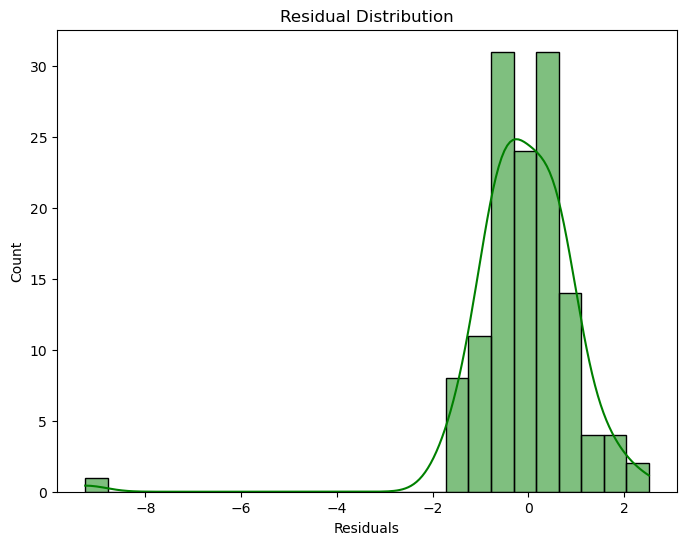

In [142]:
residuals = y_test - y_pred
plt.figure(figsize=(8, 6))
sns.histplot(residuals, kde=True, color='green')
plt.title("Residual Distribution")
plt.xlabel("Residuals")
plt.show()

In [144]:
df = pd.read_csv("winequality-white.csv", sep=';')

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.0              0.27         0.36            20.7      0.045   
1            6.3              0.30         0.34             1.6      0.049   
2            8.1              0.28         0.40             6.9      0.050   
3            7.2              0.23         0.32             8.5      0.058   
4            7.2              0.23         0.32             8.5      0.058   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 45.0                 170.0   1.0010  3.00       0.45   
1                 14.0                 132.0   0.9940  3.30       0.49   
2                 30.0                  97.0   0.9951  3.26       0.44   
3                 47.0                 186.0   0.9956  3.19       0.40   
4                 47.0                 186.0   0.9956  3.19       0.40   

   alcohol  quality  
0      8.8        6  
1      9.5        6  
2     10.1        6 

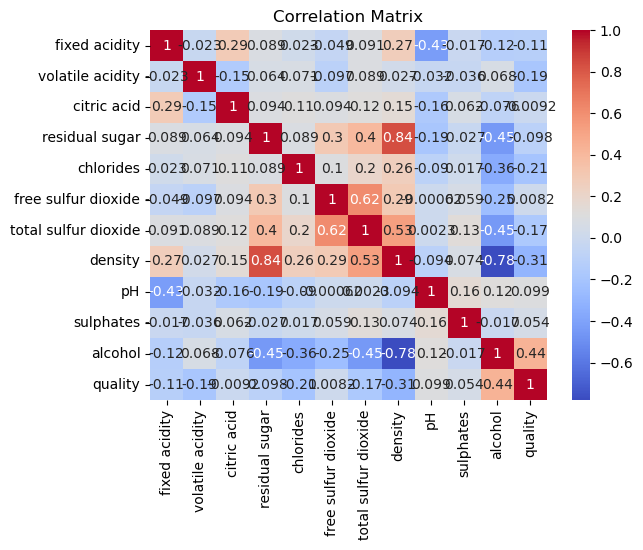

In [146]:
print(df.head())
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title('Correlation Matrix')
plt.show()

In [148]:
X = df.drop('quality', axis=1)
y = df['quality']

In [156]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [158]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [160]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [162]:
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Coefficients: [ 0.03876294 -0.1945387  -0.00734062  0.36607545 -0.00057702  0.08536602
 -0.01018555 -0.37543964  0.09020353  0.07371875  0.28116082]
Intercept: 5.871362940275645


In [164]:
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

In [166]:
print(f"MSE: {mse}, RMSE: {rmse}, MAE: {mae}")

MSE: 0.5690247717229252, RMSE: 0.7543373063311434, MAE: 0.5862665383250466


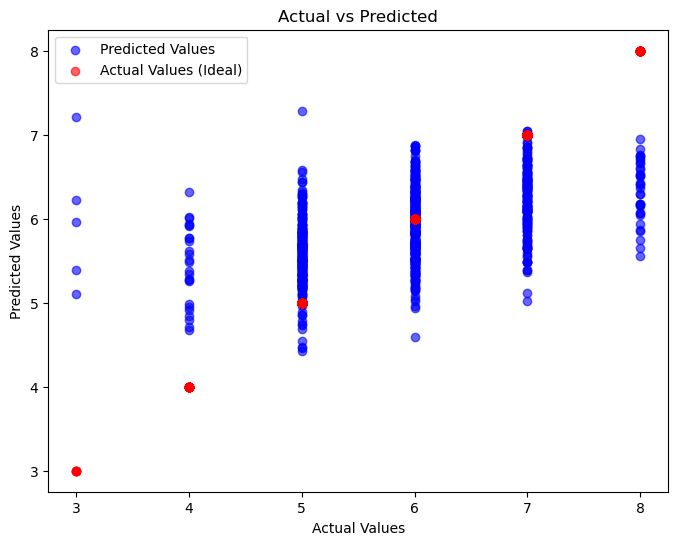

In [168]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, c='blue', alpha=0.6, label='Predicted Values')
plt.scatter(y_test, y_test, c='red', alpha=0.6, label='Actual Values (Ideal)')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted")
plt.legend()
plt.show()

In [170]:
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': model.coef_})
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)
print(feature_importance)

                 Feature  Importance
3         residual sugar    0.366075
10               alcohol    0.281161
8                     pH    0.090204
5    free sulfur dioxide    0.085366
9              sulphates    0.073719
0          fixed acidity    0.038763
4              chlorides   -0.000577
2            citric acid   -0.007341
6   total sulfur dioxide   -0.010186
1       volatile acidity   -0.194539
7                density   -0.375440
